In [ ]:
from google.colab import files

# Upload the Student Placement dataset
uploaded = files.upload()

Saving student_placement_dataset.csv to student_placement_dataset.csv


In [ ]:

# Import required libraries
import pandas as pd
import numpy as np

# Load the Student Placement dataset
df = pd.read_csv("student_placement_dataset.csv")

# Display dataset shape
print("Shape of Dataset:", df.shape)

# Display first five rows
print("\nFirst Five Rows:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical description
print("\nStatistical Description:")
display(df.describe())

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Display placement distribution
print("\nPlacement Distribution:")
print(df['Placed'].value_counts())


Shape of Dataset: (1200, 18)

First Five Rows:


,Student_ID,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular,Placed
0,STU1000,Male,Mechanical,85.2,75.9,7.17,2,0.0,3,1,65.0,Medium,1.8,Tier-3,Yes,7.98,No,No
1,STU1001,Male,IT,85.0,72.7,6.41,0,0.0,3,2,69.0,Low,2.5,Tier-3,No,12.46,Yes,Yes
2,STU1002,Female,Civil,79.7,85.1,7.46,1,1.0,2,0,72.0,Medium,7.3,Tier-3,Yes,5.70,No,Yes
3,STU1003,Female,Mechanical,81.6,67.0,4.51,1,1.0,0,3,63.0,Medium,20.3,Tier-2,Yes,3.68,No,No
4,STU1004,Male,Computer,70.5,78.8,8.19,0,0.0,2,0,62.0,High,3.5,Tier-1,No,18.97,Yes,Yes



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             1200 non-null   object 
 1   Gender                 1200 non-null   object 
 2   Branch                 1200 non-null   object 
 3   SSC_Percentage         1200 non-null   float64
 4   HSC_Percentage         1171 non-null   float64
 5   CGPA                   1144 non-null   float64
 6   Active_Backlogs        1200 non-null   int64  
 7   Internships            1150 non-null   float64
 8   Projects               1200 non-null   int64  
 9   Certifications         1200 non-null   int64  
 10  Aptitude_Score         1119 non-null   float64
 11  Communication_Skill    1141 non-null   object 
 12  Coding_Hours_Per_Week  1100 non-null   float64
 13  City_Tier              1173 non-null   object 
 14  Hostel_Resident        1200 non-nu

,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Coding_Hours_Per_Week,Family_Income_LPA
count,1200.000000,1171.000000,1144.000000,1200.000000,1150.000000,1200.000000,1200.000000,1119.000000,1100.000000,1069.000000
mean,80.210750,78.021435,6.570944,1.178333,1.002609,2.165000,1.570833,61.364611,6.934273,8.198073
std,7.881148,8.399608,1.035234,1.229956,0.897241,1.452423,1.245502,14.603686,4.687462,5.440728
min,57.100000,52.600000,4.500000,0.000000,0.000000,0.000000,0.000000,15.000000,0.100000,0.800000
25%,74.800000,72.350000,5.867500,0.000000,0.000000,1.000000,1.000000,52.000000,3.400000,4.600000
50%,80.100000,77.900000,6.610000,1.000000,1.000000,2.000000,1.000000,62.000000,5.950000,6.920000
75%,85.900000,83.600000,7.272500,2.000000,2.000000,3.000000,2.000000,71.000000,9.400000,9.900000
max,99.000000,99.000000,9.810000,6.000000,3.000000,8.000000,7.000000,100.000000,36.500000,40.100000



Missing Values:
Student_ID                 0
Gender                     0
Branch                     0
SSC_Percentage             0
HSC_Percentage            29
CGPA                      56
Active_Backlogs            0
Internships               50
Projects                   0
Certifications             0
Aptitude_Score            81
Communication_Skill       59
Coding_Hours_Per_Week    100
City_Tier                 27
Hostel_Resident            0
Family_Income_LPA        131
Extracurricular            0
Placed                     0
dtype: int64

Placement Distribution:
Placed
No     673
Yes    527
Name: count, dtype: int64


In [ ]:

# Create a copy of the original dataset
df_clean = df.copy()

# Identify numerical columns (excluding ID and target)
numeric_cols = df_clean.drop(
    columns=['Student_ID', 'Placed']
).select_dtypes(include=np.number).columns

# Identify categorical columns (excluding ID and target)
categorical_cols = df_clean.drop(
    columns=['Student_ID', 'Placed']
).select_dtypes(include='object').columns

# Fill missing numerical values using median
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill missing categorical values using mode
for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mode()[0]
    )

# Display missing values before and after cleaning
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

# Display final dataset shape
print("\nShape After Handling Missing Values:", df_clean.shape)


Missing Values Before Cleaning:
Student_ID                 0
Gender                     0
Branch                     0
SSC_Percentage             0
HSC_Percentage            29
CGPA                      56
Active_Backlogs            0
Internships               50
Projects                   0
Certifications             0
Aptitude_Score            81
Communication_Skill       59
Coding_Hours_Per_Week    100
City_Tier                 27
Hostel_Resident            0
Family_Income_LPA        131
Extracurricular            0
Placed                     0
dtype: int64

Missing Values After Cleaning:
Student_ID               0
Gender                   0
Branch                   0
SSC_Percentage           0
HSC_Percentage           0
CGPA                     0
Active_Backlogs          0
Internships              0
Projects                 0
Certifications           0
Aptitude_Score           0
Communication_Skill      0
Coding_Hours_Per_Week    0
City_Tier                0
Hostel_Resident        

In [ ]:


from sklearn.preprocessing import LabelEncoder

# Create a copy of the cleaned dataset
df_encoded = df_clean.copy()

# Identify categorical input columns
categorical_cols = df_encoded.drop(
    columns=['Student_ID', 'Placed']
).select_dtypes(include=['object']).columns

# Apply Label Encoding to categorical input columns
label_encoders = {}

for col in categorical_cols:
    encoder = LabelEncoder()
    df_encoded[col] = encoder.fit_transform(df_encoded[col])
    label_encoders[col] = encoder

# Encode target variable separately
target_encoder = LabelEncoder()
df_encoded['Placed'] = target_encoder.fit_transform(
    df_encoded['Placed']
)

# Display encoded dataset
print("Dataset After Label Encoding:")
display(df_encoded.head())

print("\nEncoded Categorical Input Columns:")
print(list(categorical_cols))

print("\nTarget Variable Encoding:")
print(dict(zip(
    target_encoder.classes_,
    target_encoder.transform(target_encoder.classes_)
)))

print("\nDataset Shape After Encoding:", df_encoded.shape)



Dataset After Label Encoding:


,Student_ID,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular,Placed
0,STU1000,1,5,85.2,75.9,7.17,2,0.0,3,1,65.0,2,1.8,2,1,7.98,0,0
1,STU1001,1,4,85.0,72.7,6.41,0,0.0,3,2,69.0,1,2.5,2,0,12.46,1,1
2,STU1002,0,0,79.7,85.1,7.46,1,1.0,2,0,72.0,2,7.3,2,1,5.70,0,1
3,STU1003,0,5,81.6,67.0,4.51,1,1.0,0,3,63.0,2,20.3,1,1,3.68,0,0
4,STU1004,1,1,70.5,78.8,8.19,0,0.0,2,0,62.0,0,3.5,0,0,18.97,1,1



Encoded Categorical Input Columns:
['Gender', 'Branch', 'Communication_Skill', 'City_Tier', 'Hostel_Resident', 'Extracurricular']

Target Variable Encoding:
{'No': np.int64(0), 'Yes': np.int64(1)}

Dataset Shape After Encoding: (1200, 18)


In [ ]:

from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df_encoded.drop(
    columns=['Student_ID', 'Placed']
)

y = df_encoded['Placed']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Original Feature Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTraining Feature Shape:", X_train.shape)
print("Testing Feature Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Original Feature Shape: (1200, 16)
Target Variable Shape: (1200,)

Training Feature Shape: (960, 16)
Testing Feature Shape: (240, 16)
Training Target Shape: (960,)
Testing Target Shape: (240,)


In [ ]:

from sklearn.preprocessing import StandardScaler

# Create StandardScaler object
scaler = StandardScaler()

# Fit scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back into DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Display scaled training data
print("Scaled Training Data:")
display(X_train_scaled.head())

# Display scaled testing data
print("\nScaled Testing Data:")
display(X_test_scaled.head())

# Display descriptive statistics
print("\nTraining Data Statistics After Scaling:")
display(X_train_scaled.describe())


Scaled Training Data:


,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular
475,-1.338170,0.970619,-0.120031,-0.884164,-0.196859,-0.140402,-0.016749,0.575485,0.323838,0.604336,0.838812,-0.204528,1.520337,-0.965189,0.501027,-0.805906
1140,0.747289,0.970619,-1.245102,0.217952,0.828027,-0.140402,-0.016749,-1.480838,-1.258272,0.107257,-1.586668,0.026119,0.194703,1.036067,-0.226423,1.240839
844,-1.338170,-0.829370,-0.120031,-1.051877,-0.227301,-0.140402,-1.165249,1.260926,-1.258272,0.746358,0.838812,-0.325343,0.194703,-0.965189,-0.723643,-0.805906
755,-1.338170,-0.829370,0.046172,0.014301,-0.907176,-0.140402,-1.165249,-0.109956,1.114893,-0.744879,-1.586668,-1.116133,-1.130932,1.036067,-0.787489,1.240839
945,-1.338170,-0.829370,0.634277,-0.800307,1.497754,-0.957284,-1.165249,0.575485,-1.258272,1.172426,0.838812,1.080506,1.520337,1.036067,-0.067777,-0.805906



Scaled Testing Data:


,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular
750,-1.338170,-0.829370,-1.040543,-0.968020,-1.049240,1.493363,-1.165249,0.575485,-0.467217,-0.176789,0.838812,-0.204528,1.520337,-0.965189,2.060402,1.240839
1040,0.747289,-0.829370,-1.104468,0.086178,1.020827,-0.140402,1.131751,1.260926,0.323838,0.036245,-0.373928,0.223817,-1.130932,-0.965189,-0.166447,1.240839
165,0.747289,0.970619,-0.605857,-1.063856,-0.562165,0.676481,-1.165249,-0.795397,1.114893,0.249279,-0.373928,2.486355,-1.130932,1.036067,0.942141,1.240839
725,0.747289,-0.829370,-0.887125,-0.824266,-1.495725,3.127127,-0.016749,-1.480838,0.323838,-0.744879,-0.373928,-0.852536,0.194703,1.036067,-0.226423,-0.805906
72,0.747289,-1.429366,1.580359,0.146075,1.365838,-0.957284,-1.165249,-0.795397,0.323838,-1.312969,-0.373928,0.157918,0.194703,-0.965189,-0.621104,-0.805906



Training Data Statistics After Scaling:


,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular
count,9.600000e+02,960.000000,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02,9.600000e+02
mean,-9.251859e-17,0.000000,-1.757853e-17,2.757054e-16,5.976701e-16,-3.330669e-17,-1.147230e-16,-1.073216e-16,1.295260e-17,-1.591320e-16,-3.700743e-17,-1.720846e-16,3.700743e-17,-9.621933e-17,2.035409e-17,-6.106227e-17
std,1.000521e+00,1.000521,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00,1.000521e+00
min,-1.338170e+00,-1.429366,-2.932707e+00,-3.052457e+00,-2.124863e+00,-9.572839e-01,-1.165249e+00,-1.480838e+00,-1.258272e+00,-3.301285e+00,-1.586668e+00,-1.489561e+00,-1.130932e+00,-9.651889e-01,-1.319534e+00,-8.059060e-01
25%,-1.338170e+00,-0.829370,-6.825666e-01,-6.565527e-01,-6.534918e-01,-9.572839e-01,-1.165249e+00,-7.953970e-01,-4.672167e-01,-6.028562e-01,-3.739282e-01,-7.427042e-01,-1.130932e+00,-9.651889e-01,-6.094957e-01,-8.059060e-01
50%,7.472895e-01,-0.229374,-1.135991e-02,-2.163801e-02,1.623582e-02,-1.404016e-01,-1.674895e-02,-1.099561e-01,-4.672167e-01,3.624534e-02,8.388119e-01,-2.045277e-01,1.947025e-01,-9.651889e-01,-2.264234e-01,-8.059060e-01
75%,7.472895e-01,0.970619,6.982014e-01,6.611948e-01,6.580581e-01,6.764806e-01,1.131751e+00,5.754847e-01,3.238381e-01,6.043356e-01,8.388119e-01,4.874136e-01,1.947025e-01,1.036067e+00,2.301678e-01,1.240839e+00
max,7.472895e-01,1.570615,2.424161e+00,2.506041e+00,3.131484e+00,3.944010e+00,2.280250e+00,4.002689e+00,4.279112e+00,2.734674e+00,8.388119e-01,6.506204e+00,1.520337e+00,1.036067e+00,6.192940e+00,1.240839e+00


In [ ]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Create SVM classifier
svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

# Train the SVM model
svm_model.fit(X_train_scaled, y_train)

# Predict placement on testing data
svm_predictions = svm_model.predict(X_test_scaled)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_predictions)

# Display results
print("Support Vector Machine (SVM)")
print("Kernel: RBF")
print("Model Accuracy:", svm_accuracy)
print("Model Accuracy Percentage:", svm_accuracy * 100, "%")


Support Vector Machine (SVM)
Kernel: RBF
Model Accuracy: 0.7666666666666667
Model Accuracy Percentage: 76.66666666666667 %


In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create Decision Tree classifier
dt_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Train the Decision Tree model
dt_model.fit(X_train_scaled, y_train)

# Predict placement on testing data
dt_predictions = dt_model.predict(X_test_scaled)

# Calculate accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)

# Display results
print("Decision Tree (CART)")
print("Splitting Criterion: Gini Impurity")
print("Model Accuracy:", dt_accuracy)
print("Model Accuracy Percentage:", dt_accuracy * 100, "%")


Decision Tree (CART)
Splitting Criterion: Gini Impurity
Model Accuracy: 0.6708333333333333
Model Accuracy Percentage: 67.08333333333333 %


In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Create KNN classifier
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the KNN model
knn_model.fit(X_train_scaled, y_train)

# Predict placement on testing data
knn_predictions = knn_model.predict(X_test_scaled)

# Calculate accuracy
knn_accuracy = accuracy_score(y_test, knn_predictions)

# Display results
print("K-Nearest Neighbors (KNN)")
print("Number of Neighbors (K): 5")
print("Model Accuracy:", knn_accuracy)
print("Model Accuracy Percentage:", knn_accuracy * 100, "%")


K-Nearest Neighbors (KNN)
Number of Neighbors (K): 5
Model Accuracy: 0.6666666666666666
Model Accuracy Percentage: 66.66666666666666 %


In [ ]:

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Create Gaussian Naive Bayes classifier
nb_model = GaussianNB()

# Train the Naive Bayes model
nb_model.fit(X_train_scaled, y_train)

# Predict placement on testing data
nb_predictions = nb_model.predict(X_test_scaled)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, nb_predictions)

# Display results
print("Naive Bayes Classifier")
print("Algorithm: Gaussian Naive Bayes")
print("Model Accuracy:", nb_accuracy)
print("Model Accuracy Percentage:", nb_accuracy * 100, "%")


Naive Bayes Classifier
Algorithm: Gaussian Naive Bayes
Model Accuracy: 0.75
Model Accuracy Percentage: 75.0 %


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)
import pandas as pd

# Store model predictions and probabilities
models = {
    'SVM': (svm_predictions, svm_model.predict_proba(X_test_scaled)),
    'Decision Tree': (dt_predictions, dt_model.predict_proba(X_test_scaled)),
    'KNN': (knn_predictions, knn_model.predict_proba(X_test_scaled)),
    'Naive Bayes': (nb_predictions, nb_model.predict_proba(X_test_scaled))
}

# Calculate evaluation metrics
results = []

for name, (predictions, probabilities) in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-Score': f1_score(y_test, predictions, zero_division=0),
        'Log Loss': log_loss(y_test, probabilities)
    })

# Create comparison DataFrame
evaluation_df = pd.DataFrame(results)

print("Classification Model Evaluation:")
display(evaluation_df.round(4))


Classification Model Evaluation:


,Model,Accuracy,Precision,Recall,F1-Score,Log Loss
0,SVM,0.7667,0.7579,0.6857,0.7200,0.4890
1,Decision Tree,0.6708,0.6275,0.6095,0.6184,11.8644
2,KNN,0.6667,0.6289,0.5810,0.6040,1.8645
3,Naive Bayes,0.7500,0.7064,0.7333,0.7196,0.5296


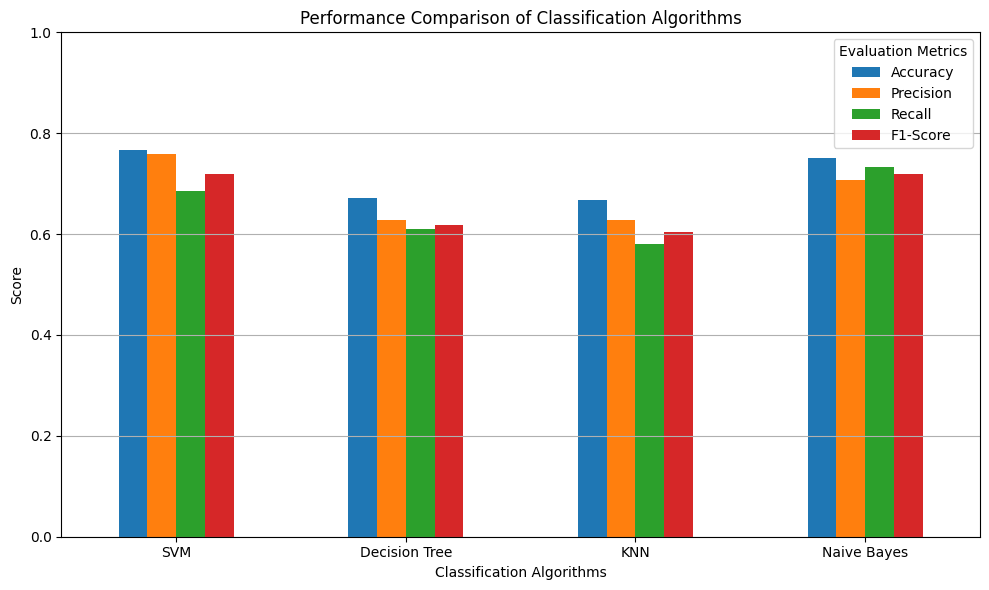

Best Performing Model Based on Accuracy: SVM


In [ ]:

import matplotlib.pyplot as plt

# Set Model as the index
comparison_df = evaluation_df.set_index('Model')

# Select classification performance metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Plot comparison of classification metrics
comparison_df[metrics].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Performance Comparison of Classification Algorithms')
plt.xlabel('Classification Algorithms')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# Display model with highest accuracy
best_model = evaluation_df.loc[
    evaluation_df['Accuracy'].idxmax(), 'Model'
]

print("Best Performing Model Based on Accuracy:", best_model)
